# Inspect a trained model

This notebook uses the same test folders and helpers as `ps_density.pipeline.test_predict`.
Coherence comes from the `tiles/` directory in `paths.yaml`. TorchGeo splits
70/15/15 inside each 1x1 degree file; a single mosaic samples different ground.
By default it loads the 2-channel paper checkpoint from Hugging Face
(`dominika-malinowska/ps_predictions`). Set `test.checkpoint` in `paths.yaml`
to a local `.ckpt` to override. It shows the input stack and a few prediction
patches. The full paper figure set stays in the script:

```bash
poetry run python -m ps_density.pipeline.test_predict
```

`plot_input_pred_patch` also needs the Google satellite folder from `paths.yaml`.
It saves a JPEG and this notebook displays that file. Change `specific_batch` and
`specific_patch` to look at another chip.


In [9]:
import os

import torch
from torch.utils.data import DataLoader
from torchgeo.datasets import BoundingBox, stack_samples
from torchgeo.datasets.splits import random_bbox_splitting
from torchgeo.samplers import GridGeoSampler
from lightning.pytorch import seed_everything
from IPython.display import Image, display

from ps_density.utils.model_checkpoint import resolve_paper_checkpoint
from ps_density.config.paths import load_paths
from ps_density.utils.prediction_plots import plot_input_pred_patch
from ps_density.utils.torchgeo_classes_def import PixelwiseRegressionTask
from ps_density.utils.torchgeo_fun_to_read_input import (
    RasterDatasetOptical_imgs,
    RasterDataset_imgs,
    RasterDataset_msks,
    plot_input,
    scale_coh,
)

_cfg = load_paths()
experiment_dir = os.path.join(
    str(_cfg.test.output.revision_results_dir), _cfg.test.output.experiment_name
)
os.makedirs(experiment_dir, exist_ok=True)

imgs = RasterDataset_imgs(
    paths=str(_cfg.test.input.coherence_summer), transforms=scale_coh
)
imgs_OSM = RasterDataset_imgs(paths=str(_cfg.test.input.osm))
msks = RasterDataset_msks(paths=str(_cfg.test.input.mask_egms))
dataset = (imgs & imgs_OSM) & msks
print("crs", dataset.crs, "res", dataset.res, "length", len(dataset))


Converting RasterDataset_imgs res from 0.0008333333333333334 to 0.00083333333
Converting RasterDataset_msks res from 0.0008333333333333334 to 0.00083333333
crs EPSG:4326 res 0.00083333333 length 1


input channels 2
mask values tensor([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
         14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,  27,
         28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,  40,  41,
         42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,  53,  54,  55,
         56,  57,  58,  59,  60,  61,  62,  63,  64,  65,  66,  67,  68,  69,
         70,  71,  72,  73,  74,  75,  76,  77,  78,  79,  80,  81,  82,  83,
         84,  85,  86,  87,  88,  89,  90,  91,  92,  93,  94,  95,  96,  97,
         98,  99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 112, 114,
        116, 117, 118, 120, 122, 123, 126, 130, 134, 135, 138, 139, 147, 150,
        152, 156, 167])


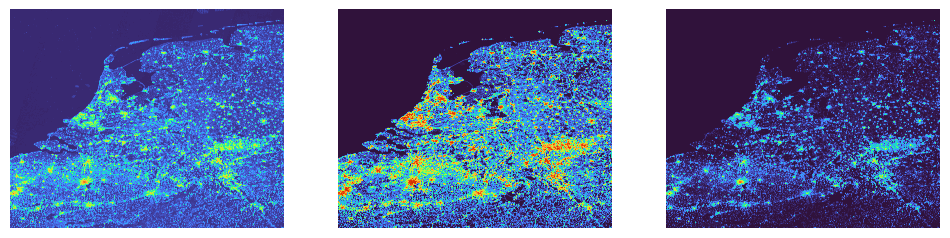

In [2]:
bounding_box = BoundingBox(
    minx=3.0,
    maxx=7.999999996,
    miny=50.000000004,
    maxy=54.0,
    mint=0.0,
    maxt=9.223372036854776e18,
)
sample = dataset[bounding_box]
print("input channels", sample["image"].shape[0])
print("mask values", torch.unique(sample["mask"]))
plot_input(sample, rows=1)


Seed set to 54321


       minx  miny  batch  i       mae
0  6.553333  52.0      0  1  1.365128




In [4]:
seed = 54321
patch_size = 64
batch_size = 16
specific_batch = 0
specific_patch = 1

seed_everything(seed, workers=True)
generator = torch.Generator().manual_seed(seed)

model = PixelwiseRegressionTask.load_from_checkpoint(
    checkpoint_path=resolve_paper_checkpoint(_cfg)
)
model.eval()

_, _, test_dataset = random_bbox_splitting(
    dataset, [0.7, 0.15, 0.15], generator=generator
)
dataloader_pred = DataLoader(
    dataset=test_dataset,
    batch_size=batch_size,
    sampler=GridGeoSampler(test_dataset, patch_size, patch_size),
    num_workers=0,
    collate_fn=stack_samples,
    generator=generator,
)
opt = RasterDatasetOptical_imgs(paths=str(_cfg.test.input.google_satellite_dir))
outputdir_plots = os.path.join(
    str(_cfg.test.output.plots_review_dir), "notebook_test_pred"
)
os.makedirs(outputdir_plots, exist_ok=True)

df_mae = plot_input_pred_patch(
    dataloader_pred,
    model,
    opt,
    batch_size,
    True,
    True,
    True,
    outputdir_plots,
    specific_batch=specific_batch,
    specific_patch=specific_patch,
)
print(df_mae)
display(
    Image(
        filename=os.path.join(
            outputdir_plots,
            "model_pred_b{0}_{1}.jpg".format(specific_batch, specific_patch),
        )
    )
)


## Plot another patch

Edit the batch and patch indices, then run this cell.


       minx  miny  batch  i       mae
0  6.713333  52.0      0  4  0.473176




In [5]:
specific_batch_2 = 0
specific_patch_2 = 4

df_mae_2 = plot_input_pred_patch(
    dataloader_pred,
    model,
    opt,
    batch_size,
    True,
    False,
    True,
    outputdir_plots,
    specific_batch=specific_batch_2,
    specific_patch=specific_patch_2,
)
print(df_mae_2)
display(
    Image(
        filename=os.path.join(
            outputdir_plots,
            "model_pred_b{0}_{1}.jpg".format(specific_batch_2, specific_patch_2),
        )
    )
)


## Rome plots

Needs the Italy folders and the Rome Google satellite raster in `paths.yaml`.
This cell only draws one patch. The full Rome prediction GeoTIFF is written by
`ps_density.pipeline.test_predict`.


Converting RasterDataset_imgs res from 0.0008333300781249997 to 0.00083333333
Converting RasterDataset_msks res from 0.0008333300781249997 to 0.00083333333
        minx       miny  batch   i      mae
0  12.633333  41.730001     10  10  5.50253




In [11]:
rome = (
    RasterDataset_imgs(paths=str(_cfg.test.rome.coherence_dir), transforms=scale_coh)
    & RasterDataset_imgs(paths=str(_cfg.test.rome.osm_dir))
    & RasterDataset_msks(paths=str(_cfg.test.rome.mask_dir))
)
rome_batch = 10
rome_patch = 10
dataloader_rome = DataLoader(
    dataset=rome,
    batch_size=batch_size,
    sampler=GridGeoSampler(rome, patch_size, patch_size),
    num_workers=0,
    collate_fn=stack_samples,
    generator=generator,
)
opt_rome = RasterDatasetOptical_imgs(paths=str(_cfg.test.rome.google_satellite_dir))
rome_plot_dir = os.path.join(str(_cfg.test.rome.plots_review_dir), "notebook_rome")
os.makedirs(rome_plot_dir, exist_ok=True)
df_rome = plot_input_pred_patch(
    dataloader_rome,
    model,
    opt_rome,
    batch_size,
    True,
    True,
    True,
    rome_plot_dir,
    specific_batch=rome_batch,
    specific_patch=rome_patch,
)
print(df_rome)
display(
    Image(
        filename=os.path.join(
            rome_plot_dir, "model_pred_b{0}_{1}.jpg".format(rome_batch, rome_patch)
        )
    )
)
